In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##**Load Dataset**

In [2]:
customer_info = pd.read_csv('/content/drive/MyDrive/THT/Cust churn/Customer_Info.csv')
location_data = pd.read_csv('/content/drive/MyDrive/THT/Cust churn/Location_Data.csv')
online_services = pd.read_csv('/content/drive/MyDrive/THT/Cust churn/Online_Services.csv')
payment_info = pd.read_csv('/content/drive/MyDrive/THT/Cust churn/Payment_Info.csv')
service_options = pd.read_csv('/content/drive/MyDrive/THT/Cust churn/Service_Options.csv')
status_analysis = pd.read_csv('/content/drive/MyDrive/THT/Cust churn/Status_Analysis.csv')

##**Data Understanding**

In [3]:
datasets = {
    "Customer Info": customer_info,
    "Location Data": location_data,
    "Online Services": online_services,
    "Payment Info": payment_info,
    "Service Options": service_options,
    "Status Analysis": status_analysis
}

summary_info = []

for name, data in datasets.items():
    summary_info.append({
        "Dataset": name,
        "Rows": data.shape[0],
        "Columns": data.shape[1],
        "Missing Value": data.isnull().sum().sum(),
        "Duplicate": data.duplicated().sum()
    })

summary_info = pd.DataFrame(summary_info)
summary_info

,Dataset,Rows,Columns,Missing Value,Duplicate
0,Customer Info,7043,9,0,0
1,Location Data,7043,8,0,0
2,Online Services,7043,11,1526,0
3,Payment Info,7043,11,0,0
4,Service Options,7043,10,3877,0
5,Status Analysis,7043,9,5174,0


In [4]:
customer_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   customer_id           7043 non-null   object
 1   gender                7043 non-null   object
 2   age                   7043 non-null   int64 
 3   under_30              7043 non-null   object
 4   senior_citizen        7043 non-null   object
 5   partner               7043 non-null   object
 6   dependents            7043 non-null   object
 7   number_of_dependents  7043 non-null   int64 
 8   married               7043 non-null   object
dtypes: int64(2), object(7)
memory usage: 495.3+ KB


No missing values were detected in this table. The next step is to review the consistency of category labels and other values.

In [5]:
location_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       7043 non-null   object 
 1   country           7043 non-null   object 
 2   state             7043 non-null   object 
 3   city              7043 non-null   object 
 4   zip_code          7043 non-null   int64  
 5   total_population  7043 non-null   int64  
 6   latitude          7043 non-null   float64
 7   longitude         7043 non-null   float64
dtypes: float64(2), int64(2), object(4)
memory usage: 440.3+ KB


This table contains no missing values. Category labels and value consistency will be reviewed before proceeding.

In [6]:
online_services.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   customer_id           7043 non-null   object
 1   phone_service         7043 non-null   object
 2   internet_service      7043 non-null   object
 3   online_security       7043 non-null   object
 4   online_backup         7043 non-null   object
 5   device_protection     7043 non-null   object
 6   premium_tech_support  7043 non-null   object
 7   streaming_tv          7043 non-null   object
 8   streaming_movies      7043 non-null   object
 9   streaming_music       7043 non-null   object
 10  internet_type         5517 non-null   object
dtypes: object(11)
memory usage: 605.4+ KB


Missing values were identified in the internet_type column. Before deciding how to handle them, the existing values and their meaning need to be examined.


In [7]:
online_services.internet_type.unique()

array(['Cable', 'Fiber Optic', 'DSL', nan], dtype=object)

In [8]:
percentage_nan_inet = online_services['internet_type'].isna().mean() * 100

print(f"Percentage of NaN inet_type: {percentage_nan_inet:.2f}%")

Percentage of NaN inet_type: 21.67%


The internet_type column has a missing-value rate of 21.67%. Because this represents a substantial share of the data, dropping these records could remove useful customer information. Based on the column's context, the missing values will be reviewed and represented as "No Internet Service" during preprocessing where appropriate.

In [9]:
payment_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 11 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   customer_id                        7043 non-null   object 
 1   contract                           7043 non-null   object 
 2   paperless_billing                  7043 non-null   object 
 3   payment_method                     7043 non-null   object 
 4   monthly_ charges                   7043 non-null   float64
 5   avg_monthly_long_distance_charges  7043 non-null   float64
 6   total_charges                      7043 non-null   float64
 7   total_refunds                      7043 non-null   float64
 8   total_extra_data_charges           7043 non-null   int64  
 9   total_long_distance_charges        7043 non-null   float64
 10  total_revenue                      7043 non-null   float64
dtypes: float64(6), int64(1), object(4)
memory usage: 605.4+ 

In [10]:
service_options.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   customer_id              7043 non-null   object
 1   tenure                   7043 non-null   int64 
 2   internet_service         7043 non-null   object
 3   phone_service            7043 non-null   object
 4   multiple_lines           7043 non-null   object
 5   avg_monthly_gb_download  7043 non-null   int64 
 6   unlimited_data           7043 non-null   object
 7   offer                    3166 non-null   object
 8   referred_a_friend        7043 non-null   object
 9   number_of_referrals      7043 non-null   int64 
dtypes: int64(3), object(7)
memory usage: 550.4+ KB


In [11]:
service_options['offer'].unique()

array([nan, 'Offer E', 'Offer D', 'Offer A', 'Offer B', 'Offer C'],
      dtype=object)

In [12]:
service_options['offer'].value_counts(dropna=False)

,count
offer,
NaN,3877
Offer B,824
Offer E,805
Offer D,602
Offer A,520
Offer C,415


In [13]:
percentage_nan_offer = service_options['offer'].isna().mean() * 100

print(f"Percentage of NaN offer: {percentage_nan_offer:.2f}%")

Percentage of NaN offer: 55.05%


More than half of the records in the offer column are missing. Rather than removing a large portion of the dataset, the records will be retained and the missing values will be handled during preprocessing using a category that reflects the meaning of the field, such as No Offer" where appropriate.

In [14]:
status_analysis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   customer_id         7043 non-null   object
 1   satisfaction_score  7043 non-null   int64 
 2   cltv                7043 non-null   int64 
 3   customer_status     7043 non-null   object
 4   churn_score         7043 non-null   int64 
 5   churn_label         7043 non-null   object
 6   churn_value         7043 non-null   int64 
 7   churn_category      7043 non-null   object
 8   churn_reason        1869 non-null   object
dtypes: int64(4), object(5)
memory usage: 495.3+ KB


In [15]:
status_analysis['churn_reason'].unique()

array([nan, 'Competitor had better devices', 'Product dissatisfaction',
       'Network reliability', 'Limited range of services',
       'Competitor made better offer', "Don't know",
       'Long distance charges', 'Attitude of service provider',
       'Attitude of support person',
       'Competitor offered higher download speeds',
       'Competitor offered more data',
       'Lack of affordable download/upload speed', 'Deceased', 'Moved',
       'Service dissatisfaction', 'Price too high',
       'Lack of self-service on Website',
       'Poor expertise of online support', 'Extra data charges',
       'Poor expertise of phone support'], dtype=object)

In [16]:
status_analysis['churn_reason'].value_counts(dropna=False)

,count
churn_reason,
NaN,5174
Competitor had better devices,313
Competitor made better offer,311
Attitude of support person,220
Don't know,130
Competitor offered more data,117
Competitor offered higher download speeds,100
Attitude of service provider,94
Price too high,78


for the missing value on churn_reason column, we're going to filled it with "No Reason"

In [17]:
status_analysis['churn_label'].unique()

array(['No', 'Yes'], dtype=object)

In [18]:
status_analysis['churn_label'].value_counts(dropna=False)

,count
churn_label,
No,5174
Yes,1869


#**DATA PREPOCESSING**

###**HANDLING MISSING VALUE**

In [19]:
online_services['internet_type'] = online_services['internet_type'].fillna('No Internet Service')

service_options['offer'] = service_options['offer'].fillna('No Offer')

status_analysis['churn_reason'] = status_analysis['churn_reason'].fillna('Not Churned')

In [20]:
for name, data in datasets.items():
    print(
        name,
        "| Rows:", len(data),
        "| Unique IDs:", data["customer_id"].nunique(),
        "| Duplicate IDs:", data["customer_id"].duplicated().sum()
    )

Customer Info | Rows: 7043 | Unique IDs: 7043 | Duplicate IDs: 0
Location Data | Rows: 7043 | Unique IDs: 7043 | Duplicate IDs: 0
Online Services | Rows: 7043 | Unique IDs: 7043 | Duplicate IDs: 0
Payment Info | Rows: 7043 | Unique IDs: 7043 | Duplicate IDs: 0
Service Options | Rows: 7043 | Unique IDs: 7043 | Duplicate IDs: 0
Status Analysis | Rows: 7043 | Unique IDs: 7043 | Duplicate IDs: 0


###**MERGE ALL DATASET**

In [21]:
from functools import reduce

dataframes = list(datasets.values())

df = reduce(
    lambda left, right: pd.merge(
        left,
        right,
        on="customer_id",
        how="inner",
        validate="one_to_one"
    ),
    dataframes
)

print("Final shape:", df.shape)
df.head()

Final shape: (7043, 53)


,customer_id,gender,age,under_30,senior_citizen,partner,dependents,number_of_dependents,married,country,...,referred_a_friend,number_of_referrals,satisfaction_score,cltv,customer_status,churn_score,churn_label,churn_value,churn_category,churn_reason
0,0002-ORFBO,Female,37,No,No,Yes,No,0,Yes,United States,...,Yes,2,3,2205,Stayed,65,No,0,Not Applicable,Not Churned
1,0003-MKNFE,Male,46,No,No,No,No,0,No,United States,...,No,0,5,5414,Stayed,66,No,0,Not Applicable,Not Churned
2,0004-TLHLJ,Male,50,No,No,No,No,0,No,United States,...,No,0,1,4479,Churned,71,Yes,1,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,No,Yes,Yes,No,0,Yes,United States,...,Yes,1,1,3714,Churned,91,Yes,1,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,No,Yes,Yes,No,0,Yes,United States,...,Yes,3,1,3464,Churned,68,Yes,1,Dissatisfaction,Network reliability


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 53 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   customer_id                        7043 non-null   object 
 1   gender                             7043 non-null   object 
 2   age                                7043 non-null   int64  
 3   under_30                           7043 non-null   object 
 4   senior_citizen                     7043 non-null   object 
 5   partner                            7043 non-null   object 
 6   dependents                         7043 non-null   object 
 7   number_of_dependents               7043 non-null   int64  
 8   married                            7043 non-null   object 
 9   country                            7043 non-null   object 
 10  state                              7043 non-null   object 
 11  city                               7043 non-null   objec

Before removing the duplicate phone_service and internet_service columns created during the merge, their values will be compared to confirm whether the two versions contain the same information.

In [23]:
print(
    "Phone Service identical:",
    df["phone_service_x"].equals(df["phone_service_y"])
)

print(
    "Internet Service identical:",
    df["internet_service_x"].equals(df["internet_service_y"])
)

Phone Service identical: True
Internet Service identical: True


The duplicated columns were checked for consistency. Where the values matched, one copy was removed and the remaining column was renamed to preserve the original field name.

In [24]:
df = df.drop(columns=[
    "phone_service_y",
    "internet_service_y"
])

df = df.rename(columns={
    "phone_service_x": "phone_service",
    "internet_service_x": "internet_service"
})

In [25]:
df = df.rename(columns={"monthly_ charges": "monthly_charges"})

The merged dataset is now consolidated, with the redundant columns addressed.

In [26]:
df_clean = df.copy()

In [27]:
print(df_clean.shape)
print(df_clean.columns.tolist())
df.info()

(7043, 51)
['customer_id', 'gender', 'age', 'under_30', 'senior_citizen', 'partner', 'dependents', 'number_of_dependents', 'married', 'country', 'state', 'city', 'zip_code', 'total_population', 'latitude', 'longitude', 'phone_service', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'premium_tech_support', 'streaming_tv', 'streaming_movies', 'streaming_music', 'internet_type', 'contract', 'paperless_billing', 'payment_method', 'monthly_charges', 'avg_monthly_long_distance_charges', 'total_charges', 'total_refunds', 'total_extra_data_charges', 'total_long_distance_charges', 'total_revenue', 'tenure', 'multiple_lines', 'avg_monthly_gb_download', 'unlimited_data', 'offer', 'referred_a_friend', 'number_of_referrals', 'satisfaction_score', 'cltv', 'customer_status', 'churn_score', 'churn_label', 'churn_value', 'churn_category', 'churn_reason']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 51 columns):
 #   Column  

##**FEATURE ENGINEERING**

In [28]:
#customer tenure group
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, float("inf")],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49+ months"
    ]
)

df[["tenure", "tenure_group"]].head()

,tenure,tenure_group
0,9,0-12 months
1,9,0-12 months
2,4,0-12 months
3,13,13-24 months
4,3,0-12 months


In [29]:
df["tenure_group"].value_counts().sort_index()

,count
tenure_group,
0-12 months,2175
13-24 months,1024
25-48 months,1594
49+ months,2239


**Feature Engineering "Customer Tenure Group"**

To make customer tenure easier to interpret, the continuous `tenure` variable was grouped into four lifecycle categories:

- **0–12 months:** New customers
- **13–24 months:** Early-tenure customers
- **25–48 months:** Established customers
- **49+ months:** Long-tenure customers

The original tenure column was retained for detailed analysis, while tenure_group provides a clearer way to compare customer segments and present lifecycle patterns in visualizations.

###**Handling outliers**

In [30]:
numeric_cols = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns

numeric_cols

Index(['age', 'number_of_dependents', 'zip_code', 'total_population',
       'latitude', 'longitude', 'monthly_charges',
       'avg_monthly_long_distance_charges', 'total_charges', 'total_refunds',
       'total_extra_data_charges', 'total_long_distance_charges',
       'total_revenue', 'tenure', 'avg_monthly_gb_download',
       'number_of_referrals', 'satisfaction_score', 'cltv', 'churn_score',
       'churn_value'],
      dtype='object')

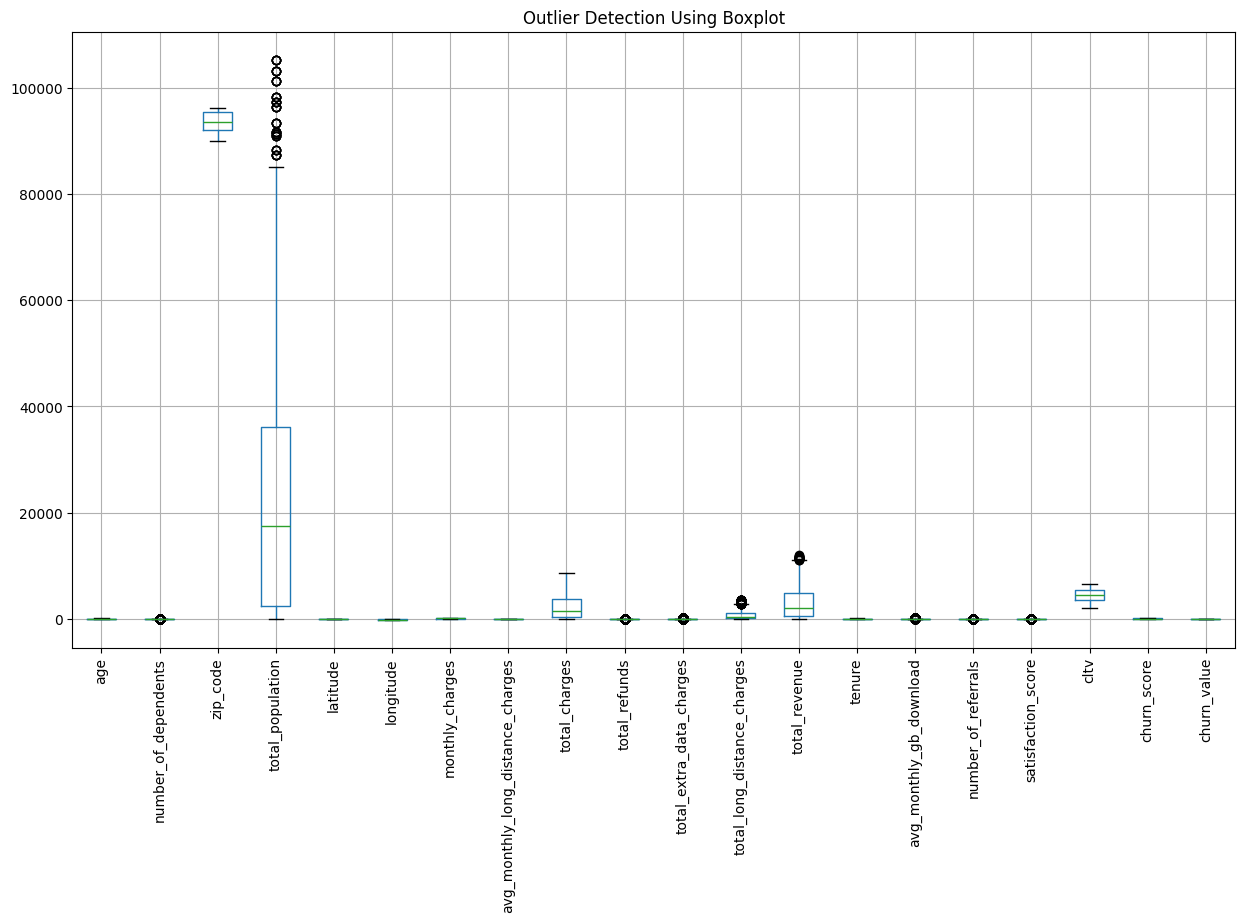

In [31]:
plt.figure(figsize=(15,8))

df_clean[numeric_cols].boxplot()

plt.xticks(rotation=90)

plt.title("Outlier Detection Using Boxplot")

plt.show()

**total_population — many high outliers**

Several observations lie above the upper whisker, indicating that some customers are associated with locations whose population values are much higher than those of most other observations. This may reflect differences in the sizes of the geographic areas represented in the dataset, rather than incorrect data.

**total_revenue — high-value outliers**

A small number of customers have substantially higher revenue values than the majority. These may be high-value customers who have spent more over their relationship with the company. Investigate whether they are associated with longer tenure, higher monthly charges, or more services.

**total_charges and total_long_distance_charges — high-value outliers**

These variables also contain observations above their upper whiskers. Customers with longer tenure or higher recurring charges may naturally accumulate higher total charges. Long-distance usage may also contribute to differences in total charges.

**Other variables — less visually prominent outliers**

Variables such as number_of_referrals, avg_monthly_gb_download, satisfaction_score, and age appear compressed near the bottom because the chart uses one shared y-axis for variables with very different scales. This does not necessarily mean they have no outliers.

The most important takeaway is that your numerical variables have very different scales and may have different distributions. This affects how you should interpret the boxplot.
- Customer spending: High values in total_charges and total_revenue could represent customers with greater cumulative spending. These customers may be valuable to the business, so removing them without investigation could distort your analysis.
- Customer tenure: tenure appears to have a much smaller range than the population and spending variables. Total charges should be interpreted alongside tenure because customers who stay longer have more time to accumulate charges.
- Geographic characteristics: Outliers in total_population may reflect differences in the locations represented in the dataset. They are not necessarily unusual customer behavior.
- Potential churn predictors: Outliers in spending and usage variables may be worth examining alongside churn status. However, this boxplot alone does not tell us whether customers with high charges are more likely to churn.

In [32]:
numeric_cols = df_clean.select_dtypes(include="number").columns

outlier_results = []

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    )

    outlier_results.append({
        "Column": col,
        "Outlier Count": outlier_mask.sum(),
        "Outlier Percentage": round(
            outlier_mask.mean() * 100, 2
        ),
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary.sort_values(
    "Outlier Percentage",
    ascending=False
)

,Column,Outlier Count,Outlier Percentage,Lower Bound,Upper Bound
1,number_of_dependents,1627,23.10,0.000000,0.000000
16,satisfaction_score,922,13.09,1.500000,5.500000
10,total_extra_data_charges,728,10.34,0.000000,0.000000
15,number_of_referrals,676,9.60,-4.500000,7.500000
9,total_refunds,525,7.45,0.000000,0.000000
14,avg_monthly_gb_download,362,5.14,-33.000000,63.000000
11,total_long_distance_charges,196,2.78,-1610.287500,2871.932500
3,total_population,57,0.81,-48327.500000,86796.500000
12,total_revenue,21,0.30,-5687.692500,11094.447500
0,age,0,0.00,-10.000000,102.000000


Potential outliers in numerical features were identified using the Interquartile Range (IQR) method. The flagged observations were not automatically removed because extreme values do not necessarily indicate data errors; they may reflect genuine differences in customer characteristics, spending, or service usage.

Removing valid observations could discard useful information, particularly for customers with unusually high charges or distinct usage patterns. Therefore, the identified outliers were retained for further analysis, while their validity should be considered in the context of each variable.

In [33]:
service_columns = [
    "phone_service",
    "online_security",
    "online_backup",
    "device_protection",
    "tech_support"
]

for col in service_columns:
    if col in df.columns:
        print(f"\n{col}")
        print(df[col].value_counts(dropna=False))


phone_service
phone_service
Yes    6361
No      682
Name: count, dtype: int64

online_security
online_security
No     5024
Yes    2019
Name: count, dtype: int64

online_backup
online_backup
No     4614
Yes    2429
Name: count, dtype: int64

device_protection
device_protection
No     4621
Yes    2422
Name: count, dtype: int64


**Data Preprocessing Summary**

### Data Preprocessing Summary

Data preprocessing was carried out to improve consistency and prepare the dataset for exploratory analysis.

Missing values in categorical columns were replaced with meaningful labels based on the context of each field, including **`No Offer`**, **`Not Churned`**, and **`No Internet Service`**, where appropriate. Duplicate records and customer IDs were checked, and data types were reviewed to ensure that numerical and categorical variables were represented correctly.

Potential outliers were identified using the Interquartile Range (IQR) method. Plausible observations were retained to preserve potentially meaningful differences in customer spending, characteristics, and service usage.

After these checks and treatments, the dataset was ready for Exploratory Data Analysis (EDA) to investigate customer behavior and patterns associated with churn.

#**EXPLORATORY DATA ANALYSIS**

##**UNIVARRIATE ENALYSIS**

###**NUMERICAL ANALYSIS**

In [34]:
numerical_cols = df_clean.select_dtypes(include=['int64','float64']).columns

numerical_cols

Index(['age', 'number_of_dependents', 'zip_code', 'total_population',
       'latitude', 'longitude', 'monthly_charges',
       'avg_monthly_long_distance_charges', 'total_charges', 'total_refunds',
       'total_extra_data_charges', 'total_long_distance_charges',
       'total_revenue', 'tenure', 'avg_monthly_gb_download',
       'number_of_referrals', 'satisfaction_score', 'cltv', 'churn_score',
       'churn_value'],
      dtype='object')

In [35]:
numerical_summary = df_clean[numerical_cols].describe()

numerical_summary

,age,number_of_dependents,zip_code,total_population,latitude,longitude,monthly_charges,avg_monthly_long_distance_charges,total_charges,total_refunds,total_extra_data_charges,total_long_distance_charges,total_revenue,tenure,avg_monthly_gb_download,number_of_referrals,satisfaction_score,cltv,churn_score,churn_value
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,46.509726,0.468692,93486.071134,22139.814568,36.197455,-119.756684,64.761692,22.958954,2280.381264,1.962182,6.860713,749.099262,3034.379056,32.371149,20.515405,1.951867,3.244924,4400.295755,58.505040,0.265370
std,16.750352,0.962802,1856.768045,21152.174407,2.468929,2.154425,30.090047,15.448113,2266.220462,7.902614,25.104978,846.660055,2865.204542,24.559481,20.418940,3.001199,1.201657,1183.057152,21.170031,0.441561
min,19.000000,0.000000,90001.000000,11.000000,32.555828,-124.301372,18.250000,0.000000,18.800000,0.000000,0.000000,0.000000,21.360000,0.000000,0.000000,0.000000,1.000000,2003.000000,5.000000,0.000000
25%,32.000000,0.000000,92101.000000,2344.000000,33.990646,-121.788090,35.500000,9.210000,400.150000,0.000000,0.000000,70.545000,605.610000,9.000000,3.000000,0.000000,3.000000,3469.000000,40.000000,0.000000
50%,46.000000,0.000000,93518.000000,17554.000000,36.205465,-119.595293,70.350000,22.890000,1394.550000,0.000000,0.000000,401.440000,2108.640000,29.000000,17.000000,0.000000,3.000000,4527.000000,61.000000,0.000000
75%,60.000000,0.000000,95329.000000,36125.000000,38.161321,-117.969795,89.850000,36.395000,3786.600000,0.000000,0.000000,1191.100000,4801.145000,55.000000,27.000000,3.000000,4.000000,5380.500000,75.500000,1.000000
max,80.000000,9.000000,96150.000000,105285.000000,41.962127,-114.192901,118.750000,49.990000,8684.800000,49.790000,150.000000,3564.720000,11979.340000,72.000000,85.000000,11.000000,5.000000,6500.000000,96.000000,1.000000


In [36]:
numerical_eda = [
    'age',
    'tenure',
    'monthly_charges',
    'total_revenue',
    'satisfaction_score',
    'cltv'
]

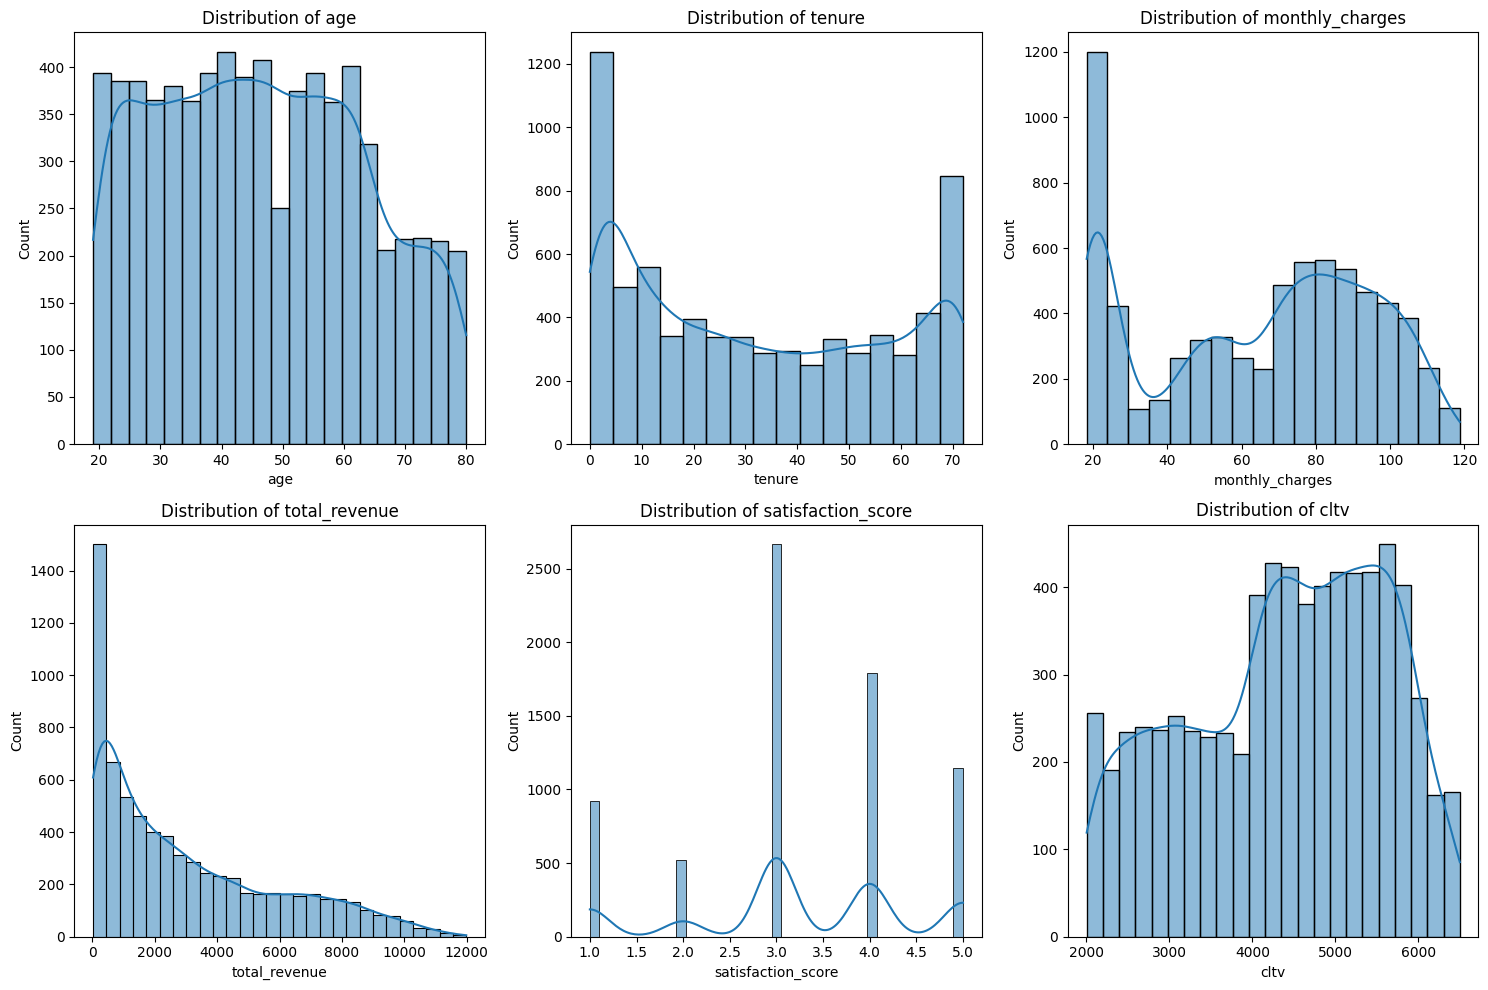

In [37]:
plt.figure(figsize=(15,10))

for i, col in enumerate(numerical_eda,1):
    plt.subplot(2,3,i)
    sns.histplot(
        data=df_clean,
        x=col,
        kde=True
    )
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

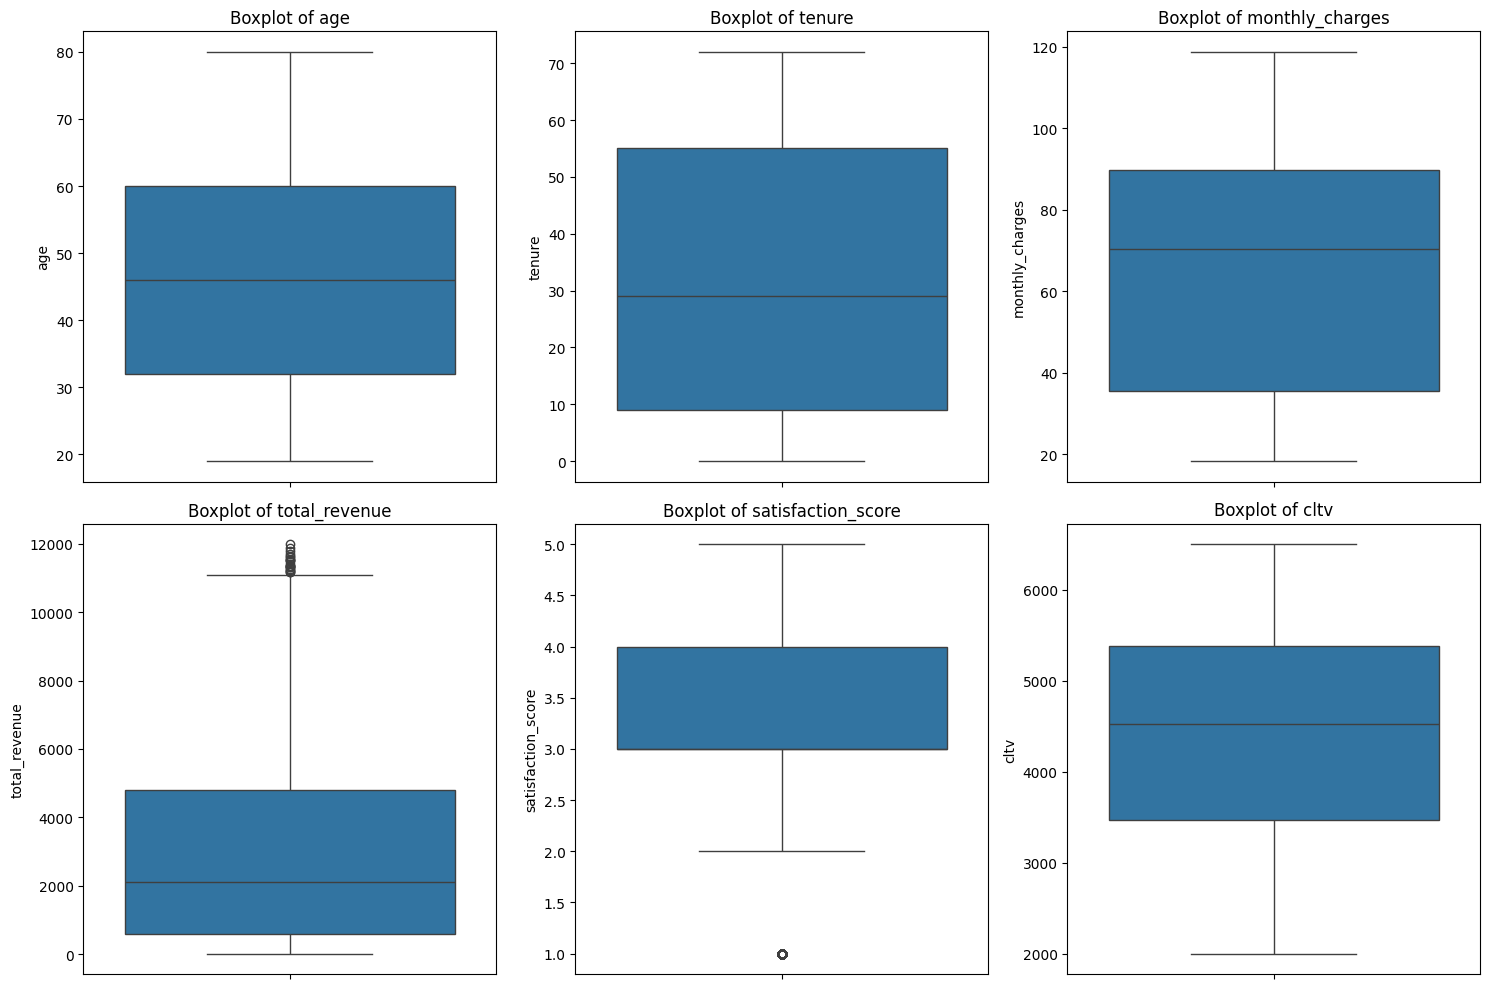

In [38]:
plt.figure(figsize=(15,10))

for i, col in enumerate(numerical_eda,1):
    plt.subplot(2,3,i)
    sns.boxplot(
        data=df_clean,
        y=col
    )
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [39]:
df_clean['churn_label'].value_counts()

,count
churn_label,
No,5174
Yes,1869


In [40]:
df_clean['churn_label'].value_counts(normalize=True)*100

,proportion
churn_label,
No,73.463013
Yes,26.536987


### Churn Distribution: Key Takeaways

- **Most customers stayed:** 5,174 customers (73.45%) did not churn.
- **Churn remains substantial:** 1,869 customers (26.55%) left the company—approximately one in four customers.
- **Implications for modeling:** The target variable is imbalanced, with more non-churners than churners. If a predictive model is developed, performance should be assessed using precision, recall, F1-score, and a confusion matrix alongside accuracy.

###**CATEGORICAL ANALYSIS**

In [41]:
categorical_cols = df_clean.select_dtypes(
    include='object'
).columns

categorical_cols

Index(['customer_id', 'gender', 'under_30', 'senior_citizen', 'partner',
       'dependents', 'married', 'country', 'state', 'city', 'phone_service',
       'internet_service', 'online_security', 'online_backup',
       'device_protection', 'premium_tech_support', 'streaming_tv',
       'streaming_movies', 'streaming_music', 'internet_type', 'contract',
       'paperless_billing', 'payment_method', 'multiple_lines',
       'unlimited_data', 'offer', 'referred_a_friend', 'customer_status',
       'churn_label', 'churn_category', 'churn_reason'],
      dtype='object')

In [42]:
categorical_cols = df_clean.select_dtypes(include='object').columns

for col in categorical_cols:
    print("="*50)
    print(col)
    print(df_clean[col].value_counts().head(10))
    print()

customer_id
customer_id
9995-HOTOH    1
0002-ORFBO    1
0003-MKNFE    1
9970-QBCDA    1
9968-FFVVH    1
9967-ATRFS    1
9965-YOKZB    1
9964-WBQDJ    1
9962-BFPDU    1
9961-JBNMK    1
Name: count, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

under_30
under_30
No     5642
Yes    1401
Name: count, dtype: int64

senior_citizen
senior_citizen
No     5901
Yes    1142
Name: count, dtype: int64

partner
partner
No     3641
Yes    3402
Name: count, dtype: int64

dependents
dependents
No     5416
Yes    1627
Name: count, dtype: int64

married
married
No     3641
Yes    3402
Name: count, dtype: int64

country
country
United States    7043
Name: count, dtype: int64

state
state
California    7043
Name: count, dtype: int64

city
city
Los Angeles      293
San Diego        285
San Jose         112
Sacramento       108
San Francisco    104
Fresno            61
Long Beach        60
Oakland           52
Escondido         51
Stockton          44
Name: count, dtype

In [43]:
categorical_eda = [
    'contract',
    'internet_service',
    'payment_method',
    'customer_status',
    'gender',
    'offer',
    'customer_status'
]

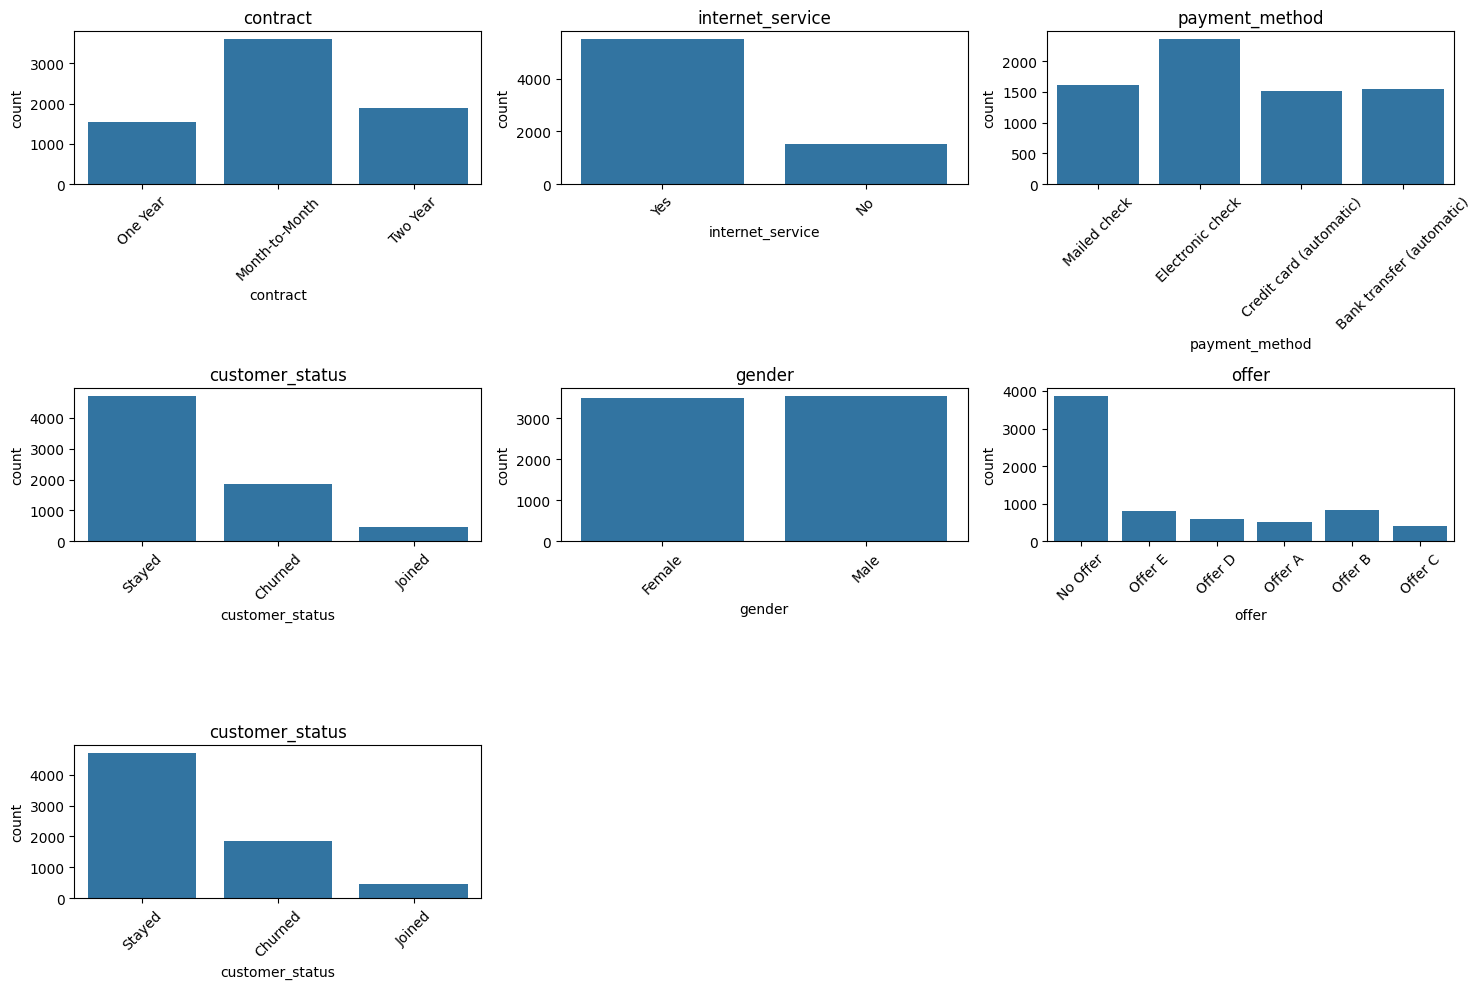

In [44]:
plt.figure(figsize=(15,10))

for i, col in enumerate(categorical_eda,1):
    plt.subplot(3,3,i)
    sns.countplot(
        data=df_clean,
        x=col
    )
    plt.title(col)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#**BIVARIATE ANALYSIS**

##**CONTRACT vs CHURN**

In [45]:
pd.crosstab(
    df_clean['contract'],
    df_clean['churn_label'],
    normalize='index'
)*100

churn_label,No,Yes
contract,,
Month-to-Month,54.155125,45.844875
One Year,89.290323,10.709677
Two Year,97.450876,2.549124


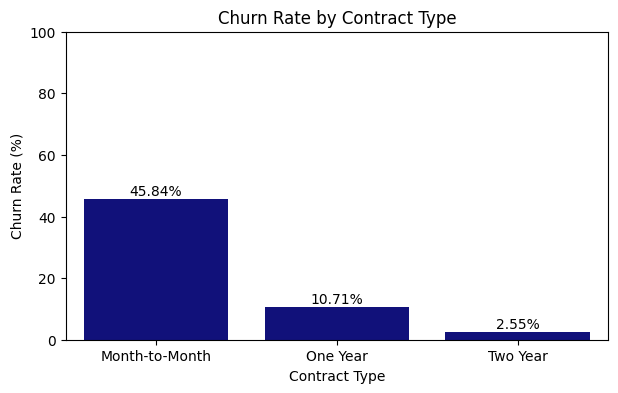

In [46]:
# Calculate churn rate
contract_churn = pd.crosstab(
    df_clean['contract'],
    df_clean['churn_label'],
    normalize='index'
) * 100

# filter the churn = yes only
churn_rate = contract_churn['Yes'].reset_index()

# Rename column
churn_rate.columns = ['Contract Type', 'Churn Rate']

# Plot
plt.figure(figsize=(7,4))

sns.barplot(
    data=churn_rate,
    x='Contract Type',
    y='Churn Rate', color="#00008b"
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

# Tambahkan label angka
for i, value in enumerate(churn_rate['Churn Rate']):
    plt.text(
        i,
        value + 1,
        f'{value:.2f}%',
        ha='center'
    )

plt.ylim(0, 100)
plt.show()

**Insight**

Customers with Month-to-Month contracts show substantially higher churn rates compared to customers with longer-term contracts.


**Interpretation**

The observed churn rate declines as contract duration increases: **45.84%** for Month-to-Month customers, **10.71%** for One-Year customers, and **2.55%** for Two-Year customers. Contract type is therefore strongly associated with churn in this dataset, with customers on shorter-term agreements showing the highest churn rate.

##**TENURE VS CHURN**

In [47]:
tenure_churn = (
    df.groupby("tenure_group", observed=False)["churn_value"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

tenure_churn.columns = [
    "Tenure Group",
    "Total Customers",
    "Churned Customers",
    "Churn Rate"
]

tenure_churn["Churn Rate"] = (
    tenure_churn["Churn Rate"] * 100
).round(2)

tenure_churn

,Tenure Group,Total Customers,Churned Customers,Churn Rate
0,0-12 months,2175,1037,47.68
1,13-24 months,1024,294,28.71
2,25-48 months,1594,325,20.39
3,49+ months,2239,213,9.51


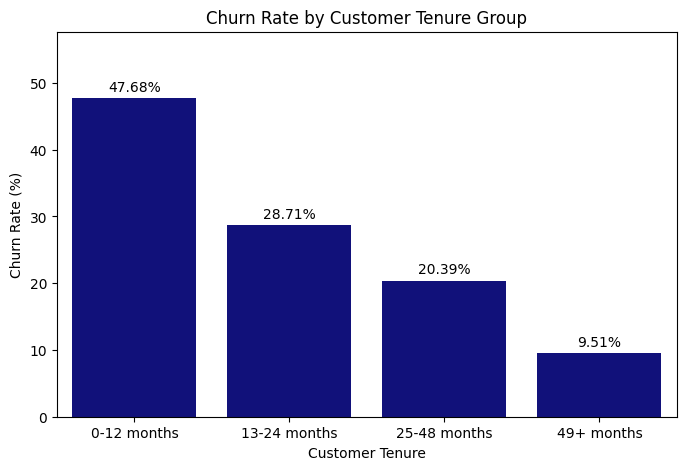

In [48]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=tenure_churn,
    x="Tenure Group",
    y="Churn Rate", color="#00008b"
)

plt.title("Churn Rate by Customer Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.ylim(0, tenure_churn["Churn Rate"].max() + 10)
plt.show()

**insight**

Churn is most concentrated among customers with shorter tenure, and the rate declines as the customer relationship becomes longer.

Customers with **0–12 months** of tenure have the highest churn rate at **47.68%**, followed by **28.71%** among those with **13–24 months**. The rate falls to **20.39%** for customers with **25–48 months** of tenure and **9.51%** for those who have stayed longer than 48 months.

**interpretation**

The early stages of the customer lifecycle are a priority for retention efforts. Improving onboarding and identifying service concerns early may help the business address risks in this segment.

##**MONTHLY CHARGE VS CHURN**

In [49]:
df_clean.groupby('churn_label')['monthly_charges'].mean()

,monthly_charges
churn_label,
No,61.265124
Yes,74.441332


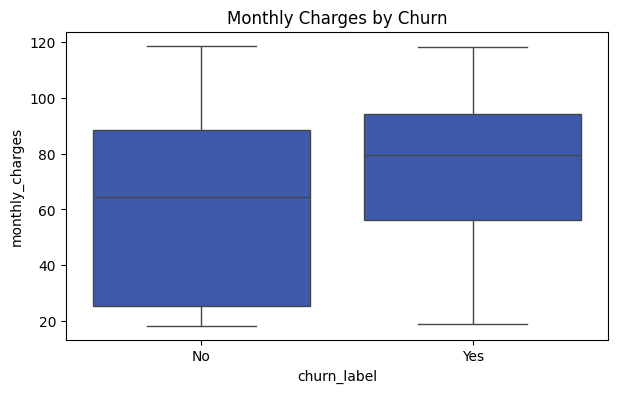

In [50]:
plt.figure(figsize=(7,4))

sns.boxplot(
    data=df_clean,
    x='churn_label',
    y='monthly_charges', color="#2a52be"
)

plt.title('Monthly Charges by Churn')

plt.show()

**Insight**

Customers who churned have higher average monthly charges than customers who stayed.

The average monthly charge is **74.44** among churned customers, compared with **61.27** among retained customers—a difference of approximately **13.18**.

**Interpretation**

Higher monthly charges are associated with churn in this dataset. Pricing, affordability, or the perceived value of the service may be relevant areas for further investigation, although this comparison does not establish a direct cause-and-effect relationship.


##**PAYMENT METHOD VS CHURN**

In [51]:
pd.crosstab(
    df_clean['payment_method'],
    df_clean['churn_label'],
    normalize='index'
)*100

churn_label,No,Yes
payment_method,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


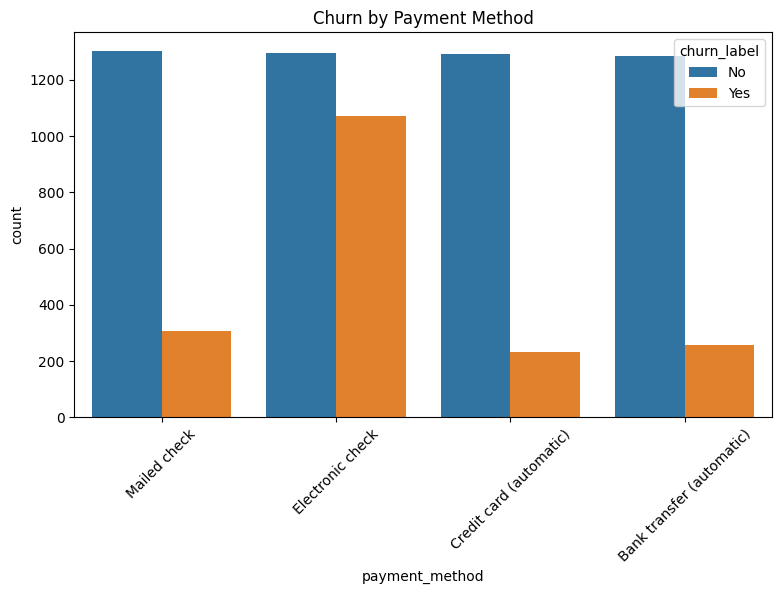

In [52]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=df_clean,
    x='payment_method',
    hue='churn_label'
)

plt.title('Churn by Payment Method')

plt.xticks(rotation=45)

plt.show()

**Insight**

Customers who use **Electronic Check** have the highest observed churn rate, at **45.29%**.

**Interpretation**

Churn is higher among Electronic Check users than among customers using automatic payment methods. This relationship may help identify a segment for further investigation, but payment method alone does not explain why customers leave.

##**INTERNET TYPE VS CHURN**

In [53]:
pd.crosstab(
    df_clean['internet_type'],
    df_clean['churn_label'],
    normalize='index'
)*100

churn_label,No,Yes
internet_type,,
Cable,74.337349,25.662651
DSL,81.416465,18.583535
Fiber Optic,59.275124,40.724876
No Internet Service,92.595020,7.404980


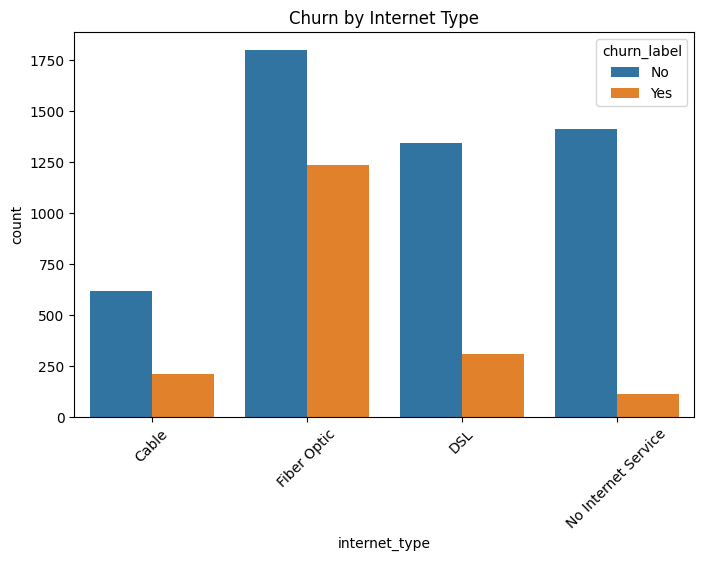

In [54]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_clean,
    x='internet_type',
    hue='churn_label'
)

plt.title('Churn by Internet Type')

plt.xticks(rotation=45)

plt.show()

Insight:
Customers using Fiber Optic service have the highest churn rate at 40.72%, followed by Cable at 25.66%, DSL at 18.58%, and No Internet Service at 7.40%.

Interpretation:
Fiber Optic customers show a higher churn rate compared to customers using other internet service types. This pattern indicates that internet service type is associated with different levels of customer churn and should be examined together with customer satisfaction and service experience.

**SATISFACTION SCORE VS CHURN**

In [55]:
df_clean.groupby('churn_label')['satisfaction_score'].mean()

,satisfaction_score
churn_label,
No,3.789911
Yes,1.736223


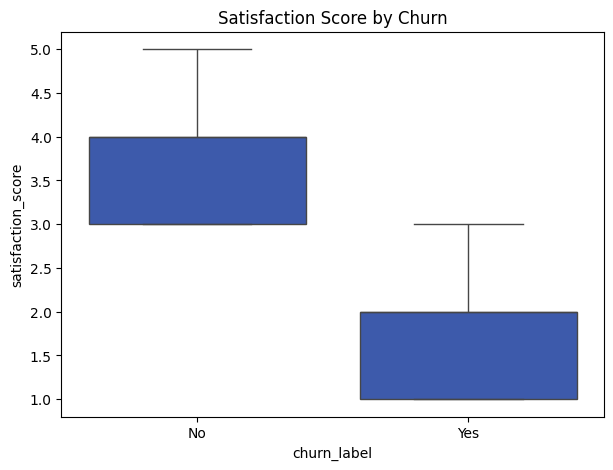

In [56]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df_clean,
    x='churn_label',
    y='satisfaction_score', color="#2a52be"
)

plt.title('Satisfaction Score by Churn')

plt.show()

**Insight**

Customers who churned reported substantially lower satisfaction scores than customers who stayed.

**Interpretation**

The average satisfaction score was **1.74** for churned customers and **3.77** for retained customers. This sizeable gap indicates a strong association between satisfaction and churn. Monitoring customer satisfaction throughout the service lifecycle may help the business identify customers who need additional support.

##**OFFER VS CHURN**

In [57]:
pd.crosstab(
    df_clean['offer'],
    df_clean['churn_label'],
    normalize='index'
)*100

churn_label,No,Yes
offer,,
No Offer,72.891411,27.108589
Offer A,93.269231,6.730769
Offer B,87.742718,12.257282
Offer C,77.108434,22.891566
Offer D,73.255814,26.744186
Offer E,47.080745,52.919255


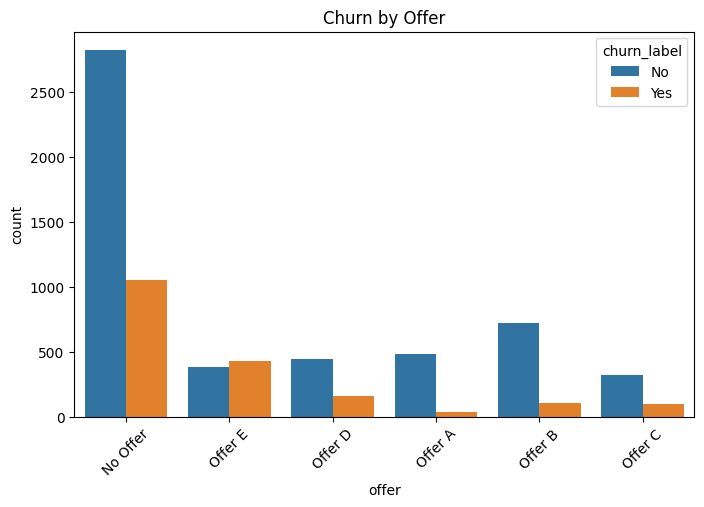

In [58]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_clean,
    x='offer',
    hue='churn_label'
)

plt.title('Churn by Offer')

plt.xticks(rotation=45)

plt.show()

**Insight**

Customers associated with **Offer E** have the highest observed churn rate among the offer groups.

**Interpretation**

Offer E has a churn rate of **52.92%**, compared with **6.73%** for Offer A and **12.26%** for Offer B. This difference makes the Offer E group a useful focus for further investigation. Customer tenure, contract type, satisfaction, and service conditions should be considered before drawing conclusions about the offer itself.

##**CORRELATION ANALYSIS**

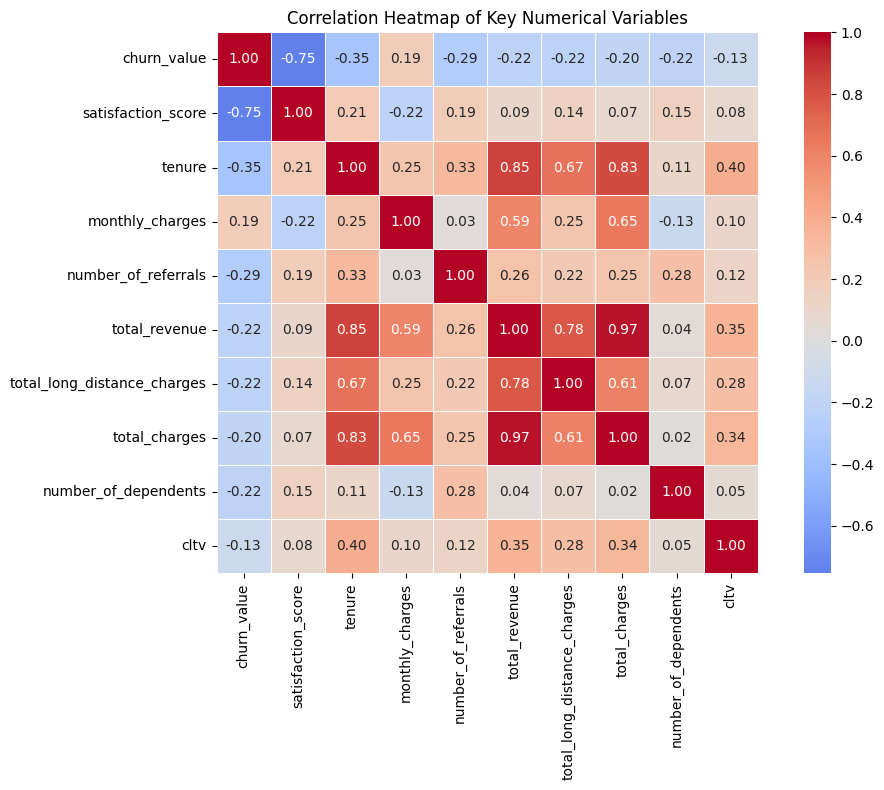

In [59]:
corr_cols = [
    'churn_value',
    'satisfaction_score',
    'tenure',
    'monthly_charges',
    'number_of_referrals',
    'total_revenue',
    'total_long_distance_charges',
    'total_charges',
    'number_of_dependents',
    'cltv'
]

corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    square=True
)

plt.title('Correlation Heatmap of Key Numerical Variables')
plt.xlabel('')
plt.ylabel('')

plt.tight_layout()
plt.show()

**Insight**

Among the selected numerical variables, satisfaction score has the strongest negative correlation with churn, followed by tenure and number of referrals. Monthly charges have a positive correlation with churn.

**Interpretation**

The correlation coefficients are **−0.75** for satisfaction score, **−0.35** for tenure, **−0.29** for number of referrals, and **0.19** for monthly charges. In this dataset, lower satisfaction, shorter tenure, fewer referrals, and higher monthly charges are associated with higher churn values. Correlation does not establish causation, so these results should be interpreted as associations rather than proof that any variable directly causes churn.

#**CHURN PATTERN ANALYSIS**

##**CONTRACT AND TENURE PATTERN**

In [60]:
df_clean.groupby(
    ['contract','churn_label'])['tenure'].mean()

contract        churn_label
Month-to-Month  No             20.172379
                Yes            14.016918
One Year        No             40.800578
                Yes            44.963855
Two Year        No             53.668665
                Yes            61.270833
Name: tenure, dtype: float64

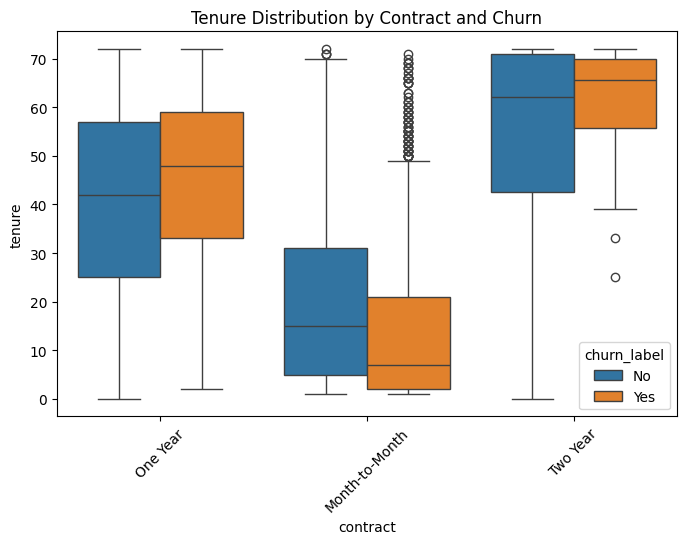

In [61]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_clean,
    x='contract',
    y='tenure',
    hue='churn_label'
)

plt.title('Tenure Distribution by Contract and Churn')

plt.xticks(rotation=45)

plt.show()

Among Month-to-Month customers, those who churned have a shorter average tenure than those who stayed. This suggests that customers with flexible contracts and shorter relationships may be more vulnerable to churn. The same tenure pattern is not as evident among One-Year and Two-Year customers, indicating that other factors may also be relevant for customers on longer-term contracts.

##**SATISFACTION AND CHURN PATTERN**

In [62]:
df_clean.groupby(
    ['customer_status']
)['satisfaction_score'].mean()

,satisfaction_score
customer_status,
Churned,1.736223
Joined,3.973568
Stayed,3.772246


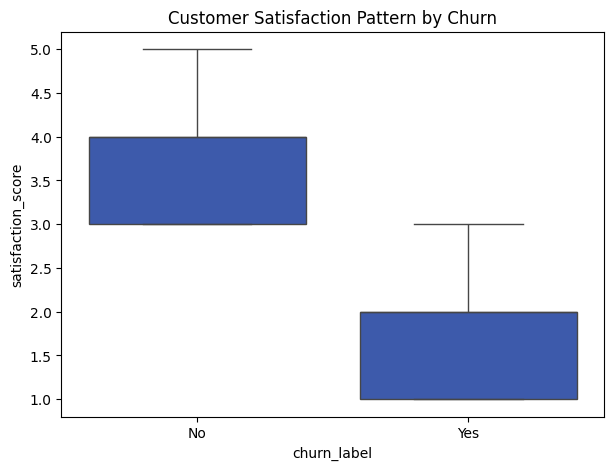

In [63]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df_clean,
    x='churn_label',
    y='satisfaction_score', color="#2a52be"
)

plt.title('Customer Satisfaction Pattern by Churn')

plt.show()

Satisfaction is closely associated with churn in the observed data. Customers who churned have an average satisfaction score of **1.74**, compared with **3.77** among retained customers. Newly joined customers have the highest average satisfaction score at **3.97**. These results highlight the importance of monitoring satisfaction over time and investigating concerns before they contribute to a customer's decision to leave.

##**SERVICE USAGE PATTERN**

In [64]:
df_clean.groupby(
    ['internet_type','churn_label']
)['satisfaction_score'].mean()

internet_type        churn_label
Cable                No             3.685575
                     Yes            1.615023
DSL                  No             3.672119
                     Yes            1.674267
Fiber Optic          No             3.753752
                     Yes            1.744337
No Internet Service  No             3.993631
                     Yes            2.044248
Name: satisfaction_score, dtype: float64

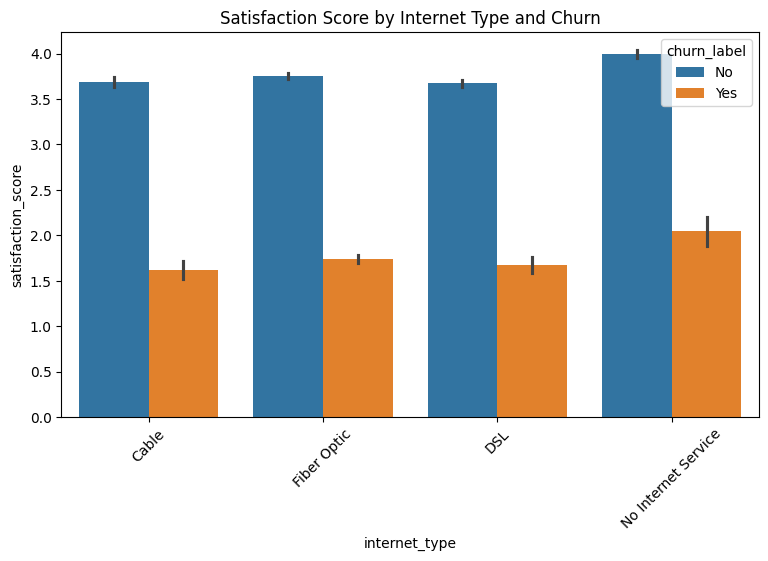

In [65]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=df_clean,
    x='internet_type',
    y='satisfaction_score',
    hue='churn_label'
)

plt.title(
    'Satisfaction Score by Internet Type and Churn'
)

plt.xticks(rotation=45)

plt.show()

Across internet service categories, customers who churned have lower satisfaction scores than customers who stayed. Fiber Optic customers also show a higher churn rate than other internet service groups. Together, these patterns suggest that satisfaction and service experience are useful areas to investigate when examining churn. The analysis shows an association, however, and does not establish that service type itself causes churn.

##**MONTHLY CHARGES AND CONTARACT PATTERN**

In [66]:
df_clean.groupby(
    ['contract','churn_label']
)['monthly_charges'].mean()

contract        churn_label
Month-to-Month  No             59.293632
                Yes            73.019396
One Year        No             63.332262
                Yes            85.050904
Two Year        No             61.806458
                Yes            86.777083
Name: monthly_charges, dtype: float64

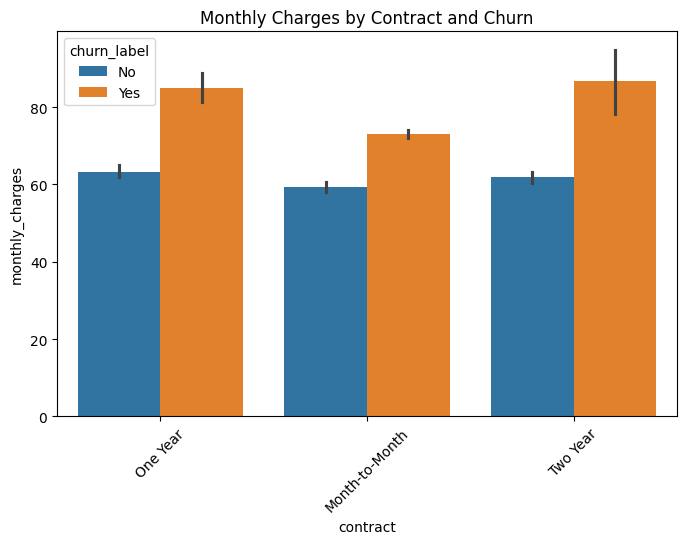

In [67]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df_clean,
    x='contract',
    y='monthly_charges',
    hue='churn_label'
)

plt.title(
    'Monthly Charges by Contract and Churn'
)

plt.xticks(rotation=45)

plt.show()

Average monthly charges vary by contract type and churn status. Within the same contract category, customers who churned tend to have higher average monthly charges than customers who remained.

##**PAYMENT METHOD PATTERN**

In [68]:
pd.crosstab(
    [
        df_clean['payment_method'],
        df_clean['contract']
    ],
    df_clean['churn_label'],
    normalize='index'
)*100

churn_label                                      No        Yes
payment_method            contract                            
Bank transfer (automatic) Month-to-Month  63.051471  36.948529
                          One Year        90.640394   9.359606
                          Two Year        96.801347   3.198653
Credit card (automatic)   Month-to-Month  64.471058  35.528942
                          One Year        90.000000  10.000000
                          Two Year        97.872340   2.127660
Electronic check          Month-to-Month  41.391509  58.608491
                          One Year        83.631714  16.368286
                          Two Year        95.323741   4.676259
Mailed check              Month-to-Month  67.548907  32.451093
                          One Year        93.294461   6.705539
                          Two Year        99.250000   0.750000

In [69]:
# Calculate the churn rate by contract and payment method
high_risk = df.groupby(['contract', 'payment_method'])['churn_label'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

# change it into a dataframe
high_risk = high_risk.reset_index()

# Rename the calculation result
high_risk.columns = ['contract', 'payment_method', 'churn_rate']

high_risk

,contract,payment_method,churn_rate
0,Month-to-Month,Bank transfer (automatic),36.948529
1,Month-to-Month,Credit card (automatic),35.528942
2,Month-to-Month,Electronic check,58.608491
3,Month-to-Month,Mailed check,32.451093
4,One Year,Bank transfer (automatic),9.359606
5,One Year,Credit card (automatic),10.000000
6,One Year,Electronic check,16.368286
7,One Year,Mailed check,6.705539
8,Two Year,Bank transfer (automatic),3.198653
9,Two Year,Credit card (automatic),2.127660


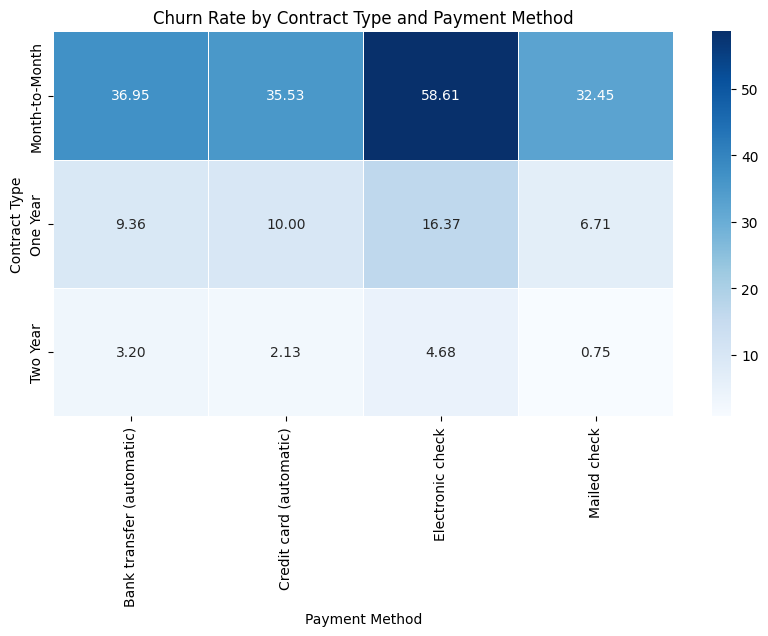

In [70]:
heatmap_data = high_risk.pivot(
    index='contract',
    columns='payment_method',
    values='churn_rate'
)

plt.figure(figsize=(10,5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Churn Rate by Contract Type and Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Contract Type")

plt.show()

Contract type remains an important feature in the payment-method comparison. Across payment methods, Month-to-Month customers show higher churn rates than customers with One-Year or Two-Year contracts. The highest observed rate is **58.61%** among Electronic Check users with Month-to-Month contracts. Customers on longer-term contracts show substantially lower churn rates, indicating stronger retention in these groups.

#**SUMMARY**

## Summary of Key Findings

The exploratory analysis identified several customer characteristics associated with churn.

1. **Customer satisfaction has the strongest numerical association with churn.** Satisfaction score has a negative correlation with churn (**r ≈ −0.75**). Customers who churned have an average satisfaction score of **1.74**, compared with **3.77** among retained customers.

2. **Month-to-Month contracts have the highest churn rate.** The churn rate is approximately **45.84%** for Month-to-Month customers, compared with **2.55%** for customers on Two-Year contracts.

3. **Churn is concentrated among early-tenure customers.** The churn rate declines from **47.44%** among customers with 0–12 months of tenure to **28.71%** for 13–24 months, **20.39%** for 25–48 months, and **9.51%** for customers with more than 48 months of tenure.

4. **Churned customers have higher average monthly charges.** Their average is approximately **74.44**, compared with **61.27** among retained customers. This is an association and does not show that higher charges directly cause churn.

5. **Some customer groups have notably higher churn rates.** Differences appear across payment methods, internet service types, offers, and contract combinations. For example, Electronic Check users with Month-to-Month contracts have an observed churn rate of approximately **58.61%**.

Overall, churn appears to be associated with several factors—including customer satisfaction, contract type, tenure, monthly charges, and service/payment patterns—rather than one single characteristic.

##**BUSINESS INSIGHTS**

Churn is not evenly distributed across the customer base; several customer groups show notably higher churn rates.

Low satisfaction is an important signal to investigate, while Month-to-Month contracts and shorter tenure are associated with higher churn. Customers with higher monthly charges also show higher churn on average.

These patterns provide an opportunity to make retention efforts more targeted. Rather than applying the same approach to every customer, the business can prioritize customers who display multiple characteristics associated with higher churn.

##**BUSINESS RECOMMENDATIONS**

1. **Address low customer satisfaction:** Review feedback and service issues, and follow up with customers reporting poor experiences.
2. **Prioritize Month-to-Month customers:** Test targeted retention outreach and communicate suitable longer-term plan options without assuming that contract length alone explains churn.
3. **Strengthen early-lifecycle support:** Improve onboarding and check in with new customers before the first year, when the observed churn rate is highest.
4. **Review pricing and perceived value:** Examine whether higher monthly charges align with customer expectations, usage, and satisfaction.
5. **Investigate high-risk combinations:** Give particular attention to groups such as Electronic Check users with Month-to-Month contracts, and validate the underlying reasons before choosing an intervention.

#**SAVING THE DATASET**

In [71]:
# Create the final cleaned dataset
df_clean = df.copy()

# Final quality check
print("Final dataset shape:", df_clean.shape)
print("Total customers:", df_clean["customer_id"].nunique())
print("Duplicate customer IDs:", df_clean["customer_id"].duplicated().sum())
print("Total missing values:", df_clean.isnull().sum().sum())

# Export dataset
df_clean.to_csv("customer_churn_clean.csv", index=False)

Final dataset shape: (7043, 52)
Total customers: 7043
Duplicate customer IDs: 0
Total missing values: 11


In [72]:
from google.colab import files

files.download("customer_churn_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>